Accuracy: 38.10%
Precision: 38.46%
Recall: 50.00%


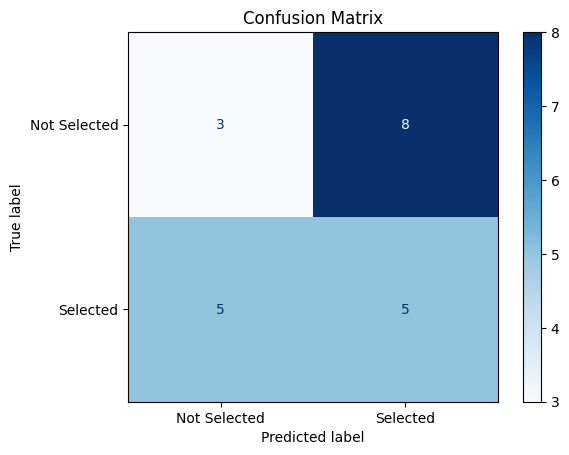

                            Feature  Coefficient
6     Domain Applied_Graphic Design     0.610570
7    Domain Applied_Web Development     0.600904
5  Domain Applied_Digital Marketing     0.397575
1                     has_portfolio    -0.000127
3           statement_quality_score    -0.091640
0                 num_skills_listed    -0.145709
4       Domain Applied_Data Science    -0.169184
2     prior_hackathon_participation    -0.469701


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(42)
n = 120
df = pd.DataFrame({
    'Applicant Name': [f'Applicant {i+1}' for i in range(n)],
    'Email': [f'applicant{i+1}@example.com' for i in range(n)],
    'Domain Applied': np.random.choice(['Web Development','Data Science','Graphic Design','Content Writing','Digital Marketing'], size=n),
    'Status': np.random.choice(['Selected','Rejected','Under Review'], size=n, p=[0.35,0.50,0.15])
})
df['num_skills_listed'] = np.random.randint(1, 9, size=len(df))
df['has_portfolio'] = np.random.choice(['Yes','No'], size=len(df), p=[0.4,0.6])
df['prior_hackathon_participation'] = np.random.choice(['Yes','No'], size=len(df), p=[0.3,0.7])
df['statement_quality_score'] = np.random.randint(1, 11, size=len(df))

df['has_portfolio'] = df['has_portfolio'].map({'Yes':1,'No':0})
df['prior_hackathon_participation'] = df['prior_hackathon_participation'].map({'Yes':1,'No':0})
df['target'] = df['Status'].apply(lambda x: 1 if x=='Selected' else 0)
df_model = df[df['Status']!='Under Review'].copy()
df_model = pd.get_dummies(df_model, columns=['Domain Applied'], drop_first=True)

feature_columns = ['num_skills_listed','has_portfolio','prior_hackathon_participation','statement_quality_score'] + [c for c in df_model.columns if c.startswith('Domain Applied_')]
X = df_model[feature_columns]; y = df_model['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.2%}")
print(f"Recall: {recall_score(y_test, y_pred, zero_division=0):.2%}")

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Selected','Selected'])
disp.plot(cmap='Blues'); plt.title('Confusion Matrix'); plt.show()

coef = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_[0]}).sort_values(by='Coefficient', ascending=False)
print(coef)